# CS 4700: Gamma Memory Triage

**Status:** primary v0.7 is the current 400-row working primary-eligible dataset; no model training, evaluation, split assignment, or runtime integration has been performed.

This notebook studies one narrow question: can a small text classifier help decide whether an individual Gamma-style memory candidate should be kept or skipped? It does not import Gamma runtime code or change Gamma memory behavior.


## 1. Project goal and research question

The labels are `keep` and `skip`. The first model-selection goal is high mean cross-validation precision for `keep`, while requiring mean cross-validation `keep` recall of at least 0.50. This is a research criterion, not a production guarantee or deployment threshold.

**Research question:** How well do simple rule and TF-IDF classifiers distinguish durable, reusable memory candidates from temporary or low-value candidates in a manually authored Gamma-style dataset?

## 2. Dataset provenance, privacy, and labeling guide

The current canonical working dataset contains 57 primary-eligible rows preserved from pilot v0.3, 50 owner-approved assistant-assisted drafts from each of Batch 01 through Batch 06, and 43 owner-approved assistant-assisted drafts from Batch 07. Batch 07 uses release `primary_v0_7`. Pilot v0.3 remains unchanged as the 60-row labeling-guide validation source dataset; all seven batch draft CSVs remain source-review provenance. The canonical dataset has 400 rows (200 `keep`, 200 `skip`), contains no policy-only rows, and does not estimate production prevalence.

All examples are newly authored and privacy-safe rather than copied from conversations, memory rows, runtime databases, logs, stream traces, usernames, identifiers, secrets, or private files. Assistant-assisted authoring may create style bias. All 400 rows remain primary eligible with `split=unassigned`; no model training, evaluation, split assignment, or runtime integration has been performed. See `../docs/labeling_guide.md`, `../docs/dataset_card.md`, and `../docs/batch_07_migration_record.md`.


## 3. Reproducibility settings and dependency check

The setup below uses a fixed seed and locates the repository without assuming that Jupyter started in one exact directory. Dependency checks do not install packages or modify manifests.

In [1]:
from pathlib import Path
import importlib.util
import random

RANDOM_SEED = 4700
PILOT_REVIEW_COMPLETE = True
EXPANDED_DATASET_READY = False
FINAL_EVALUATION_APPROVED = False
random.seed(RANDOM_SEED)

PROJECT_RELATIVE_DATA = Path("research/cs4700_memory_triage/data/memory_triage_primary_dataset.csv")

def find_repo_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / PROJECT_RELATIVE_DATA).is_file():
            return candidate
    raise FileNotFoundError("Could not locate the Gamma repository root and canonical primary dataset CSV.")

REPO_ROOT = find_repo_root(Path.cwd())
DATA_PATH = REPO_ROOT / PROJECT_RELATIVE_DATA

PACKAGE_IMPORTS = {
    "pandas": "pandas",
    "scikit-learn": "sklearn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
}
PACKAGE_AVAILABILITY = {name: importlib.util.find_spec(module) is not None for name, module in PACKAGE_IMPORTS.items()}

print(f"Repository root: {REPO_ROOT}")
print(f"Dataset path: {DATA_PATH.relative_to(REPO_ROOT)}")
print(f"Random seed: {RANDOM_SEED}")
print("Optional package availability:", PACKAGE_AVAILABILITY)
print("Training ready:", PILOT_REVIEW_COMPLETE and EXPANDED_DATASET_READY)


Repository root: /home/neety/Documents/gamma-main
Dataset path: research/cs4700_memory_triage/data/memory_triage_primary_dataset.csv
Random seed: 4700
Optional package availability: {'pandas': True, 'scikit-learn': True, 'matplotlib': True, 'seaborn': False}
Training ready: False


## 4. Load and validate the dataset schema

This execution-disabled validation scaffold predates Batch 02 and is retained without execution in this migration. Before any separately approved notebook work, its expected counts must be reconciled to the current canonical release. It does not assign splits or prove label quality.


In [2]:
import csv
import re
from collections import Counter, defaultdict
from statistics import mean, median

EXPECTED_COLUMNS = [
    "example_id", "source_record_id", "candidate_text", "label",
    "candidate_type", "candidate_source", "source_group_id",
    "paraphrase_group_id", "rationale_code", "labeler_id",
    "label_confidence", "guide_version", "privacy_checked",
    "primary_eligible", "batch_id", "dataset_release", "notes", "split",
]
ALLOWED_LABELS = {"keep", "skip"}
ALLOWED_CONFIDENCE = {"high", "medium", "low"}

with DATA_PATH.open(newline="", encoding="utf-8") as handle:
    reader = csv.DictReader(handle)
    if reader.fieldnames != EXPECTED_COLUMNS:
        raise ValueError(f"Unexpected CSV columns: {reader.fieldnames}")
    records = list(reader)

ids = [row["example_id"] for row in records]
label_counts = Counter(row["label"] for row in records)
validation_errors = []
if len(records) != 400:
    validation_errors.append(f"expected 400 rows, found {len(records)}")
if len(ids) != len(set(ids)):
    validation_errors.append("example_id values are not unique")
if label_counts != Counter({"keep": 200, "skip": 200}):
    validation_errors.append(f"unexpected class counts: {dict(label_counts)}")
for line_number, row in enumerate(records, start=2):
    if not row["candidate_text"].strip():
        validation_errors.append(f"line {line_number}: blank candidate_text")
    if row["label"] not in ALLOWED_LABELS:
        validation_errors.append(f"line {line_number}: invalid label")
    if row["label_confidence"] not in ALLOWED_CONFIDENCE:
        validation_errors.append(f"line {line_number}: invalid label_confidence")
    if row["privacy_checked"] != "true":
        validation_errors.append(f"line {line_number}: privacy_checked is not true")
    if row["primary_eligible"] != "true":
        validation_errors.append(f"line {line_number}: row is not primary eligible")
    if row["split"] != "unassigned":
        validation_errors.append(f"line {line_number}: split is assigned")

if validation_errors:
    raise ValueError("Dataset validation failed:\n- " + "\n- ".join(validation_errors))

print(f"Validated {len(records)} primary-eligible rows with {len(ids)} unique IDs.")
print("Class counts:", dict(label_counts))
print("Split counts:", dict(Counter(row["split"] for row in records)))
print("Important: schema validation does not prove label quality or authorize training.")


Validated 400 primary-eligible rows with 400 unique IDs.
Class counts: {'keep': 200, 'skip': 200}
Split counts: {'unassigned': 400}
Important: schema validation does not prove label quality or authorize training.


## 5. Exploratory data analysis

The next cells inspect class balance, missing text, duplicates, text length, rationale codes, source styles, and representative anonymized examples. Empty outputs in this committed notebook are intentional; no results have been fabricated.

In [3]:
label_counts = Counter(row["label"] for row in records)
total_rows = len(records)
primary_eligible_rows = [row for row in records if row["primary_eligible"] == "true"]
policy_only_rows = [row for row in records if row["primary_eligible"] == "false"]
class_summary = {label: {"count": count, "percent": round(100 * count / total_rows, 1)} for label, count in sorted(label_counts.items())}
blank_ids = [row["example_id"] for row in records if not row["candidate_text"].strip()]

def normalize_text(text: str) -> str:
    compact = " ".join(text.casefold().split())
    return re.sub(r"[^a-z0-9 ]+", "", compact)

exact_groups = defaultdict(list)
for row in records:
    exact_groups[normalize_text(row["candidate_text"])].append(row["example_id"])
exact_duplicate_groups = [group for group in exact_groups.values() if len(group) > 1]

print("Class summary:", class_summary)
print("Row counts:", {"total": total_rows, "primary_eligible": len(primary_eligible_rows), "policy_only": len(policy_only_rows)})
print("Primary-eligible class counts:", dict(Counter(row["label"] for row in primary_eligible_rows)))
print("Blank candidate IDs:", blank_ids)
print("Exact duplicate groups:", exact_duplicate_groups)

Class summary: {'keep': {'count': 200, 'percent': 50.0}, 'skip': {'count': 200, 'percent': 50.0}}
Row counts: {'total': 400, 'primary_eligible': 400, 'policy_only': 0}
Primary-eligible class counts: {'keep': 200, 'skip': 200}
Blank candidate IDs: []
Exact duplicate groups: []


### Near-duplicate review support

Automatic similarity is only a review aid. It must not assign labels or data splits. The code checks documented paraphrase groups and also suggests high string-similarity pairs for manual review.

In [4]:
from difflib import SequenceMatcher

paraphrase_groups = defaultdict(list)
for row in records:
    paraphrase_groups[row["paraphrase_group_id"]].append((row["example_id"], row["label"]))
documented_near_duplicates = {group: members for group, members in paraphrase_groups.items() if len(members) > 1}
cross_label_groups = {group: members for group, members in documented_near_duplicates.items() if len({label for _, label in members}) > 1}

similarity_suggestions = []
for index, left in enumerate(records):
    for right in records[index + 1:]:
        score = SequenceMatcher(None, normalize_text(left["candidate_text"]), normalize_text(right["candidate_text"])).ratio()
        if score >= 0.72:
            similarity_suggestions.append((round(score, 3), left["example_id"], right["example_id"]))

print("Documented multi-row paraphrase groups:", documented_near_duplicates)
print("Cross-label paraphrase groups requiring review:", cross_label_groups)
print("String-similarity suggestions (manual review only):", sorted(similarity_suggestions, reverse=True))

Documented multi-row paraphrase groups: {}
Cross-label paraphrase groups requiring review: {}
String-similarity suggestions (manual review only): []


Word length summary: {'min': 5, 'median': 22.0, 'mean': 21.93, 'max': 41}
Rationale distribution: {'accessibility_preference': 13, 'assistant_reaction': 3, 'casual_reaction': 8, 'context_dependent': 34, 'current_turn_only': 15, 'durable_correction': 10, 'durable_preference': 34, 'meaningful_milestone': 15, 'one_off_detail': 77, 'ongoing_commitment': 18, 'outdated_or_superseded': 13, 'recurring_constraint': 34, 'reusable_rule': 31, 'speculative_or_unclear': 35, 'stable_project_fact': 23, 'stable_relationship': 22, 'temporary_state': 15}
Candidate-source distribution: {'assistant_assisted_draft': 343, 'manual_explicit_save_style': 2, 'manual_llm_style': 17, 'manual_review_revision': 33, 'manual_rule_style': 5}
Candidate-type distribution: {'boundary': 81, 'episodic': 82, 'preference': 70, 'profile': 39, 'project': 128}


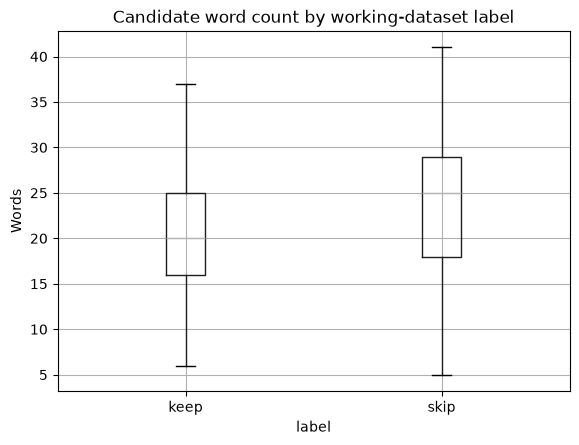

In [5]:
word_lengths = [len(row["candidate_text"].split()) for row in records]
rationale_counts = Counter(row["rationale_code"] for row in records)
source_counts = Counter(row["candidate_source"] for row in records)
type_counts = Counter(row["candidate_type"] for row in records)

print("Word length summary:", {"min": min(word_lengths), "median": median(word_lengths), "mean": round(mean(word_lengths), 2), "max": max(word_lengths)})
print("Rationale distribution:", dict(sorted(rationale_counts.items())))
print("Candidate-source distribution:", dict(sorted(source_counts.items())))
print("Candidate-type distribution:", dict(sorted(type_counts.items())))

if PACKAGE_AVAILABILITY["pandas"] and PACKAGE_AVAILABILITY["matplotlib"]:
    import pandas as pd
    import matplotlib.pyplot as plt
    frame = pd.DataFrame(records)
    frame["word_count"] = frame["candidate_text"].str.split().str.len()
    frame.boxplot(column="word_count", by="label")
    plt.suptitle("")
    plt.title("Candidate word count by working-dataset label")
    plt.ylabel("Words")
    plt.show()
else:
    print("Optional pandas/matplotlib plot skipped because packages are unavailable.")

In [6]:
sample_rng = random.Random(RANDOM_SEED)
for label in sorted(ALLOWED_LABELS):
    candidates = [row for row in primary_eligible_rows if row["label"] == label]
    sample = sample_rng.sample(candidates, k=min(3, len(candidates)))
    print(f"\nRepresentative working-dataset {label} examples:")
    for row in sample:
        print(f"- {row['example_id']}: {row['candidate_text']}")

print("Policy-only example IDs are reported separately:", [row["example_id"] for row in policy_only_rows])


Representative working-dataset keep examples:
- mtp_0019: Generated datasets must exclude secrets and private identifiers.
- mtb02_0017: In Riverbench the weekly coverage figure measures reviewed scenarios rather than executed requests so planning uses it as a review-completeness measure.
- mtb03_0023: The recovery exercise for Harborlight established that the operations group maintains restore procedures while service owners verify recovered business behavior.

Representative working-dataset skip examples:
- mtb07_0038: After the Claybird Workshop session, the supply steward counted 37 unused binding strips; the count describes that session's remainder and sets neither workshop capacity nor a replenishment rule.
- mtb01_0038: For the answer about the checksum mismatch, include only the core cause and omit background detail.
- mtp_0048: The user requested a playful tone for the reply about the mockup.
Policy-only example IDs are reported separately: []


## 6. Data-cleaning and leakage-prevention plan

Before modeling: expand the current working dataset, remove privacy failures, resolve low-confidence cases, review exact/near duplicates, and finalize source/paraphrase groups. All current rows are primary eligible, but training, tuning, and splitting remain disabled until cleaning and grouping are complete and a final holdout is frozen.


In [7]:
primary_text_records = [row for row in records if row["primary_eligible"] == "true"]
policy_demo_records = [row for row in records if row["primary_eligible"] == "false"]

print(f"Primary text-only rows in working primary v0.1: {len(primary_text_records)}")
print("Primary text-only class counts:", dict(Counter(row["label"] for row in primary_text_records)))
print("Policy-only rows in canonical dataset:", [row["example_id"] for row in policy_demo_records])
print("All splits remain unassigned; these are not final training-set counts.")


Primary text-only rows in working primary v0.1: 400
Primary text-only class counts: {'keep': 200, 'skip': 200}
Policy-only rows in canonical dataset: []
All splits remain unassigned; these are not final training-set counts.


## 7. Group-aware split strategy and final untouched test set

Do not assign splits until the dataset is expanded, cleaned, and grouping review is complete. Keep every source group and paraphrase group within one split. Freeze one grouped final test set before fitting TF-IDF, selecting rules, tuning hyperparameters, or selecting a decision threshold.


In [8]:
def modeling_is_ready() -> bool:
    return PILOT_REVIEW_COMPLETE and EXPANDED_DATASET_READY and FINAL_EVALUATION_APPROVED

if not modeling_is_ready():
    print("NOT READY: expand, clean, and group the dataset, then freeze the final holdout before training or evaluation.")
else:
    # Future work: build one stable group key from source_group_id and paraphrase_group_id,
    # reserve the grouped final holdout, and save the split manifest.
    raise NotImplementedError("Implement the reviewed group-aware split in a later approved pass.")


NOT READY: expand, clean, and group the dataset, then freeze the final holdout before training or evaluation.


## 8. Rule/keyword baseline

The rule baseline should be simple and documented. It is useful for comparison, not as ground truth. The draft function below is defined but not evaluated until the reviewed dataset and splits are ready.

In [9]:
DURABLE_TERMS = {"always", "never", "prefer", "must", "ongoing", "recurring"}
TEMPORARY_TERMS = {"today", "tonight", "right now", "current reply", "this conversation", "temporary"}

def keyword_baseline(text: str) -> str:
    lowered = text.casefold()
    if any(term in lowered for term in TEMPORARY_TERMS):
        return "skip"
    if any(term in lowered for term in DURABLE_TERMS):
        return "keep"
    return "skip"

if modeling_is_ready():
    print("Future work: evaluate keyword_baseline on development folds only.")
else:
    print("NOT READY: rule-baseline metrics are intentionally not computed.")

NOT READY: rule-baseline metrics are intentionally not computed.


## 9. Majority-class baseline

Use scikit-learn's `DummyClassifier(strategy='most_frequent')` after the grouped split is frozen. The near-balanced working dataset does not represent production prevalence.

In [10]:
if modeling_is_ready():
    from sklearn.dummy import DummyClassifier
    majority_baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_SEED)
    print("Majority baseline defined; fit only on a reviewed development split.")
else:
    print("NOT READY: majority-baseline fitting is intentionally disabled.")

NOT READY: majority-baseline fitting is intentionally disabled.


## 10. TF-IDF model comparison framework

Planned models are Logistic Regression, Linear SVM, Decision Tree, and Random Forest. Each model belongs in a scikit-learn pipeline so TF-IDF is fitted inside each development fold. No pipeline is fitted in this scaffold.

In [11]:
def build_model_pipelines():
    if not modeling_is_ready():
        raise RuntimeError("Dataset review/expansion is incomplete; do not build or fit models yet.")
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.svm import LinearSVC
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier

    def pipeline(classifier):
        return Pipeline([("tfidf", TfidfVectorizer()), ("classifier", classifier)])

    return {
        "logistic_regression": pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_SEED)),
        "linear_svm": pipeline(LinearSVC(random_state=RANDOM_SEED)),
        "decision_tree": pipeline(DecisionTreeClassifier(random_state=RANDOM_SEED)),
        "random_forest": pipeline(RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1)),
    }

print("Model factory defined. No model has been built or fitted.")

Model factory defined. No model has been built or fitted.


## 11. Cross-validation and model-specific tuning plan

Use grouped, stratified development folds and separate parameter grids. Discard configurations with mean cross-validation `keep` recall below 0.50, then rank eligible configurations by mean cross-validation `keep` precision. Report all required metrics and fold variation; do not optimize or inspect the final test set.

In [12]:
MODEL_GRIDS = {
    "logistic_regression": {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], "classifier__C": [0.1, 1.0, 10.0], "classifier__class_weight": [None, "balanced"]},
    "linear_svm": {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], "classifier__C": [0.1, 1.0, 10.0], "classifier__class_weight": [None, "balanced"]},
    "decision_tree": {"tfidf__ngram_range": [(1, 1), (1, 2)], "classifier__max_depth": [3, 5, 10, None], "classifier__min_samples_leaf": [1, 2, 4], "classifier__class_weight": [None, "balanced"]},
    "random_forest": {"tfidf__ngram_range": [(1, 1), (1, 2)], "classifier__n_estimators": [100, 300], "classifier__max_depth": [5, 10, None], "classifier__min_samples_leaf": [1, 2, 4], "classifier__class_weight": [None, "balanced"]},
}

def select_by_research_criterion(cv_rows):
    eligible = [row for row in cv_rows if row["mean_cv_keep_recall"] >= 0.50]
    return sorted(eligible, key=lambda row: row["mean_cv_keep_precision"], reverse=True)

if modeling_is_ready():
    print("Future work: run model-specific GridSearchCV with StratifiedGroupKFold and multiple scorers.")
else:
    print("NOT READY: tuning is intentionally disabled; no CV results exist.")

NOT READY: tuning is intentionally disabled; no CV results exist.


## 12. Final metrics, confusion matrix, precision-recall discussion, and error analysis

After model selection is complete, evaluate exactly once on the untouched grouped test set. Report per-class precision, recall, F1, support, accuracy, confusion matrix, and preferably PR-AUC/precision-recall curves where the selected model provides a suitable score. Inspect every false `keep` and summarize false `skip` patterns.

This section intentionally contains placeholders rather than invented charts or metrics.

In [13]:
final_test_metrics = None
final_confusion_matrix = None
final_error_analysis = None

if not FINAL_EVALUATION_APPROVED:
    print("NOT READY: the final test set is not frozen and no final metrics have been computed.")
else:
    raise NotImplementedError("Add one-time final evaluation only after model selection is frozen.")

NOT READY: the final test set is not frozen and no final metrics have been computed.


## 13. Limitations and future advisory-only Gamma integration

The manually authored balanced dataset will not estimate real Gamma candidate prevalence. A single text cannot reveal stored-memory duplicates, contradictions, owner intent, or full conversation context. Probability calibration is deferred until a separate privacy-reviewed, production-like sample exists.

A later Gamma integration may score candidates immediately before existing upsert logic in `MemoryService.persist_candidates()`, but it must start advisory-only, disabled by default, preserve the current integer return contract, and keep explicit owner save requests as an override or separate evaluation group. This notebook does not implement that integration.

## 14. First reproducible baseline experiment

This is the first baseline classifier experiment for the completed dataset. It predicts whether a privacy-safe synthetic memory candidate is labeled `keep` or `skip`. The model is advisory research only: it is not an automatic memory-writing system, cannot write memories, and has no connection to Gamma runtime behavior. Runtime integration is explicitly out of scope.

In [14]:
from pathlib import Path
import pandas as pd

BASELINE_SEED = 4700
BASELINE_RELATIVE_DATA = Path("research/cs4700_memory_triage/data/memory_triage_primary_dataset.csv")
BASELINE_EXPECTED_SCHEMA = [
    "example_id", "source_record_id", "candidate_text", "label",
    "candidate_type", "candidate_source", "source_group_id",
    "paraphrase_group_id", "rationale_code", "labeler_id",
    "label_confidence", "guide_version", "privacy_checked",
    "primary_eligible", "batch_id", "dataset_release", "notes", "split",
]

def locate_baseline_data(start=Path.cwd()):
    for candidate in (start.resolve(), *start.resolve().parents):
        path = candidate / BASELINE_RELATIVE_DATA
        if (candidate / "pyproject.toml").is_file() and path.is_file():
            return path
    raise FileNotFoundError("Could not locate the canonical memory-triage CSV.")

baseline_data_path = locate_baseline_data()
baseline_df = pd.read_csv(baseline_data_path, keep_default_na=False)
assert list(baseline_df.columns) == BASELINE_EXPECTED_SCHEMA
assert len(baseline_df) == 400
assert baseline_df["label"].value_counts().to_dict() == {"keep": 200, "skip": 200}
assert baseline_df["primary_eligible"].astype(str).str.lower().eq("true").all()
assert baseline_df["split"].eq("unassigned").all()
assert baseline_df["candidate_text"].astype(str).str.strip().ne("").all()
assert baseline_df["label"].astype(str).str.strip().ne("").all()
assert baseline_df["example_id"].is_unique

display(pd.DataFrame({
    "value": [len(baseline_df), baseline_df["example_id"].nunique(), baseline_df["candidate_text"].str.split().str.len().median()],
}, index=["rows", "unique example IDs", "median text words"]))
display(baseline_df["label"].value_counts().rename_axis("label").to_frame("count"))
display(baseline_df["candidate_type"].value_counts().rename_axis("candidate_type").to_frame("count"))
print("Validated canonical dataset:", baseline_data_path.relative_to(baseline_data_path.parents[3]))

,value
rows,400.0
unique example IDs,400.0
median text words,22.0


,count
label,
keep,200
skip,200


,count
candidate_type,
project,128
episodic,82
boundary,81
preference,70
profile,39


Validated canonical dataset: research/cs4700_memory_triage/data/memory_triage_primary_dataset.csv


### Leakage-risk inspection and in-memory split

Group identifiers are inspected only to detect leakage risk; they are never model features. Unique documented groups reduce known paraphrase leakage, but they cannot eliminate unrecorded semantic neighbors or common authoring patterns. If every paraphrase group is unique, the experiment uses a deterministic label-stratified row split and reports that limitation. If repeated paraphrase groups are present, the code stops rather than silently allowing a group to cross splits. The test set is not used for model or hyperparameter selection, and split assignments remain only in memory.

In [15]:
from sklearn.model_selection import train_test_split

group_rows = []
for column in ["paraphrase_group_id", "source_group_id"]:
    sizes = baseline_df.groupby(column, dropna=False).size()
    group_rows.append({"group column": column, "unique groups": len(sizes), "multi-row groups": int((sizes > 1).sum()), "largest group": int(sizes.max())})
group_summary = pd.DataFrame(group_rows)
display(group_summary)
normalized_text = baseline_df["candidate_text"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
exact_duplicate_count = int(normalized_text.duplicated(keep=False).sum())
print("Rows participating in exact normalized-text duplicates:", exact_duplicate_count)
assert exact_duplicate_count == 0

paraphrase_sizes = baseline_df.groupby("paraphrase_group_id", dropna=False).size()
if (paraphrase_sizes > 1).any():
    raise RuntimeError("Repeated paraphrase groups require a feasible group-disjoint stratified split; row-level splitting is prohibited.")

train_df, remainder_df = train_test_split(
    baseline_df, test_size=0.30, random_state=BASELINE_SEED, stratify=baseline_df["label"],
)
validation_df, test_df = train_test_split(
    remainder_df, test_size=0.50, random_state=BASELINE_SEED, stratify=remainder_df["label"],
)
split_frames = {"train": train_df, "validation": validation_df, "test": test_df}
split_counts = pd.concat(
    {name: frame["label"].value_counts().sort_index() for name, frame in split_frames.items()}, axis=1
).T.rename_axis("split")
display(split_counts)
assert split_counts.sum(axis=1).to_dict() == {"train": 280, "validation": 60, "test": 60}
assert not (set(train_df.index) & set(validation_df.index) or set(train_df.index) & set(test_df.index) or set(validation_df.index) & set(test_df.index))
print("Strategy: deterministic row-level label-stratified split because all paraphrase groups are unique.")
print("Limitation: unique documented groups do not rule out unrecorded semantic-neighbor leakage.")

,group column,unique groups,multi-row groups,largest group
0,paraphrase_group_id,400,0,1
1,source_group_id,400,0,1


Rows participating in exact normalized-text duplicates: 0


label,keep,skip
split,,
train,140,140
validation,30,30
test,30,30


Strategy: deterministic row-level label-stratified split because all paraphrase groups are unique.
Limitation: unique documented groups do not rule out unrecorded semantic-neighbor leakage.


### TF-IDF and Logistic Regression baseline

Each candidate pipeline is fitted only on training text and scored only on validation labels. Selection uses validation macro F1, with smaller `C` winning an exact tie; accuracy is supporting context. Only `candidate_text` enters the model. The test set remains untouched during selection. After selection, one fresh pipeline is fitted on combined train and validation rows, then evaluated once on the test rows.

In [16]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score, precision_recall_fscore_support)
from sklearn.pipeline import Pipeline

def make_baseline_pipeline(c_value):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
        ("classifier", LogisticRegression(C=c_value, random_state=BASELINE_SEED, max_iter=5000)),
    ])

selection_rows = []
for c_value in [0.25, 1.0, 4.0]:
    candidate_model = make_baseline_pipeline(c_value)
    candidate_model.fit(train_df["candidate_text"], train_df["label"])
    validation_predictions = candidate_model.predict(validation_df["candidate_text"])
    precision, recall, keep_f1, _ = precision_recall_fscore_support(
        validation_df["label"], validation_predictions, labels=["keep"], average=None, zero_division=0
    )
    selection_rows.append({
        "C": c_value,
        "validation accuracy": accuracy_score(validation_df["label"], validation_predictions),
        "validation keep precision": precision[0],
        "validation keep recall": recall[0],
        "validation keep F1": keep_f1[0],
        "validation macro F1": f1_score(validation_df["label"], validation_predictions, average="macro"),
    })
selection_results = pd.DataFrame(selection_rows).sort_values("C").reset_index(drop=True)
best_row = selection_results.sort_values(["validation macro F1", "C"], ascending=[False, True]).iloc[0]
selected_c = float(best_row["C"])
display(selection_results.round(3))
print(f"Selected C={selected_c:g} by validation macro F1; test data remained untouched during selection.")

development_df = pd.concat([train_df, validation_df], axis=0)
final_model = make_baseline_pipeline(selected_c)
final_model.fit(development_df["candidate_text"], development_df["label"])
test_predictions = final_model.predict(test_df["candidate_text"])
test_keep_probability = final_model.predict_proba(test_df["candidate_text"])[:, list(final_model.named_steps["classifier"].classes_).index("keep")]
test_keep_precision, test_keep_recall, test_keep_f1, _ = precision_recall_fscore_support(
    test_df["label"], test_predictions, labels=["keep"], average=None, zero_division=0
)
test_metrics = {
    "accuracy": accuracy_score(test_df["label"], test_predictions),
    "keep precision": test_keep_precision[0],
    "keep recall": test_keep_recall[0],
    "keep F1": test_keep_f1[0],
    "macro F1": f1_score(test_df["label"], test_predictions, average="macro"),
}
display(pd.Series(test_metrics, name="held-out test").round(3).to_frame())
print(classification_report(test_df["label"], test_predictions, labels=["keep", "skip"], digits=3, zero_division=0))
print(f"Balanced-label chance reference: 50.0% accuracy; observed held-out accuracy: {test_metrics['accuracy']:.1%}. This descriptive comparison is not a significance claim.")

,C,validation accuracy,validation keep precision,validation keep recall,validation keep F1,validation macro F1
0,0.25,0.883,0.897,0.867,0.881,0.883
1,1.00,0.883,0.897,0.867,0.881,0.883
2,4.00,0.883,0.897,0.867,0.881,0.883


Selected C=0.25 by validation macro F1; test data remained untouched during selection.


,held-out test
accuracy,0.950
keep precision,0.935
keep recall,0.967
keep F1,0.951
macro F1,0.950


              precision    recall  f1-score   support

        keep      0.935     0.967     0.951        30
        skip      0.966     0.933     0.949        30

    accuracy                          0.950        60
   macro avg      0.951     0.950     0.950        60
weighted avg      0.951     0.950     0.950        60

Balanced-label chance reference: 50.0% accuracy; observed held-out accuracy: 95.0%. This descriptive comparison is not a significance claim.


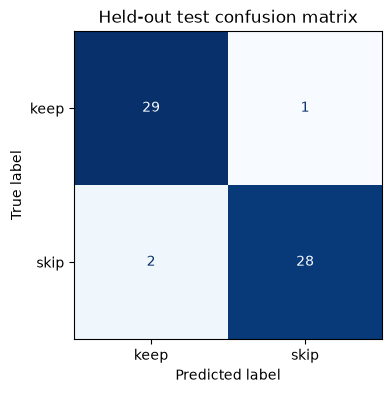

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

test_confusion = confusion_matrix(test_df["label"], test_predictions, labels=["keep", "skip"])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(test_confusion, display_labels=["keep", "skip"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Held-out test confusion matrix")
plt.show()

### Error analysis and possible-shortcut diagnostic

The tables below show the most confident incorrect predictions, not candidates for relabeling. All three errors are close to the 0.50 decision boundary. The two false positives use specific project or game language for facts that are release-local or bracket-local, while the false negative states a durable role boundary using a longer contrast with `not` and `when`. This suggests the model can miss scope and durability even when wording sounds concrete. The strongest coefficients are dominated by common surface words plus terms such as `before`, `when`, `prefers`, `session`, and `rule`; no project-domain name appears in the displayed strongest list. These associations may reflect wording shortcuts rather than the intended policy distinction, and they are not causal explanations. This is an initial diagnostic, not proof of reliability.

In [18]:
error_table = test_df[["example_id", "label", "candidate_text"]].copy()
error_table["predicted label"] = test_predictions
error_table["model confidence for keep"] = test_keep_probability
error_table = error_table.rename(columns={"label": "true label"})
error_columns = ["example_id", "true label", "predicted label", "model confidence for keep", "candidate_text"]
false_positives = error_table[(error_table["true label"] == "skip") & (error_table["predicted label"] == "keep")].sort_values("model confidence for keep", ascending=False).head(5)
false_negatives = error_table[(error_table["true label"] == "keep") & (error_table["predicted label"] == "skip")].sort_values("model confidence for keep", ascending=True).head(5)
print("False positives (most confident incorrect keep predictions):")
display(false_positives[error_columns].round({"model confidence for keep": 3}))
print("False negatives (most confident incorrect skip predictions):")
display(false_negatives[error_columns].round({"model confidence for keep": 3}))

vectorizer = final_model.named_steps["tfidf"]
classifier = final_model.named_steps["classifier"]
feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
keep_coefficients = coefficients if classifier.classes_[1] == "keep" else -coefficients
ranked = pd.DataFrame({"n-gram": feature_names, "coefficient toward keep": keep_coefficients})
strongest_keep = ranked.nlargest(12, "coefficient toward keep")
strongest_skip = ranked.nsmallest(12, "coefficient toward keep")
print("Strongest n-grams associated with keep:")
display(strongest_keep.reset_index(drop=True))
print("Strongest n-grams associated with skip:")
display(strongest_skip.reset_index(drop=True))
print("Interpretation prompt: compare the errors and coefficient lists for surface wording, domain names, and durability or temporary-time language that may be carrying too much weight. This is an initial diagnostic, not proof of model reliability or causality.")

False positives (most confident incorrect keep predictions):


,example_id,true label,predicted label,model confidence for keep,candidate_text
99,mtb01_0043,skip,keep,0.514,"Before release, the Meridian Retrieval Study s..."
339,mtb06_0033,skip,keep,0.501,An account in Bramblewake Racing shows rank se...


False negatives (most confident incorrect skip predictions):


,example_id,true label,predicted label,model confidence for keep,candidate_text
270,mtb05_0014,keep,skip,0.498,"In Juniper Gate, the service coordinator—not t..."


Strongest n-grams associated with keep:


,n-gram,coefficient toward keep
0,before,0.310311
1,when,0.231094
2,changes,0.182551
3,and,0.171639
4,first,0.151693
5,each,0.144543
6,me,0.133445
7,across,0.127685
8,prefers,0.125863
9,evidence,0.125033


Strongest n-grams associated with skip:


,n-gram,coefficient toward keep
0,the,-0.511729
1,no,-0.324324
2,but,-0.253794
3,was,-0.210906
4,one,-0.197818
5,sample,-0.183637
6,because,-0.169751
7,during,-0.167414
8,but the,-0.153422
9,not,-0.147730


Interpretation prompt: compare the errors and coefficient lists for surface wording, domain names, and durability or temporary-time language that may be carrying too much weight. This is an initial diagnostic, not proof of model reliability or causality.


### Baseline limitations

The corpus is synthetic and relatively small. Semantic-neighbor leakage may still exist even after documented group and duplicate checks. Held-out performance does not establish safe production behavior, and this classifier cannot write memories automatically. Any future runtime use would require separate design, review, and owner approval.

## Robustness Checks and Limits of the Baseline

The held-out baseline score was strong, but a strong score alone does not prove that the classifier learned the intended durability rule. The earlier coefficient inspection suggested that surface-wording shortcuts may contribute to its decisions. The checks below use only the original training and validation portions; the held-out test set is excluded from every new choice, comparison, feature inspection, and conclusion. These are exploratory development diagnostics, not a replacement-model search or a production memory system.

### Development-split integrity

The original deterministic assignment is recreated in memory with the documented two-stage, label-stratified split and `random_state=4700`. Group IDs and batch IDs are used only for diagnostics, never as model features. Unique documented source and paraphrase groups reduce direct group leakage, but they do not eliminate semantic-neighbor leakage.

In [19]:
from sklearn.model_selection import train_test_split

robust_train_df, robust_remainder_df = train_test_split(
    baseline_df, test_size=0.30, random_state=4700, stratify=baseline_df["label"],
)
robust_validation_df, robust_test_df = train_test_split(
    robust_remainder_df, test_size=0.50, random_state=4700, stratify=robust_remainder_df["label"],
)
assert set(robust_train_df.index) == set(train_df.index)
assert set(robust_validation_df.index) == set(validation_df.index)
assert set(robust_test_df.index) == set(test_df.index)
robust_split_counts = pd.concat({
    "train": robust_train_df["label"].value_counts().sort_index(),
    "validation": robust_validation_df["label"].value_counts().sort_index(),
    "test": robust_test_df["label"].value_counts().sort_index(),
}, axis=1).T.rename_axis("split")
display(robust_split_counts)
assert robust_split_counts.to_dict(orient="index") == {
    "train": {"keep": 140, "skip": 140},
    "validation": {"keep": 30, "skip": 30},
    "test": {"keep": 30, "skip": 30},
}
integrity_rows = []
for group_column in ["paraphrase_group_id", "source_group_id"]:
    integrity_rows.append({
        "check": group_column,
        "rows": len(baseline_df),
        "unique values": baseline_df[group_column].nunique(dropna=False),
        "all unique": baseline_df[group_column].nunique(dropna=False) == len(baseline_df),
    })
robust_normalized_text = baseline_df["candidate_text"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
integrity_rows.append({"check": "normalized candidate_text", "rows": len(baseline_df), "unique values": robust_normalized_text.nunique(), "all unique": robust_normalized_text.is_unique})
robust_integrity_summary = pd.DataFrame(integrity_rows)
display(robust_integrity_summary)
assert robust_integrity_summary["all unique"].all()
print("All source/paraphrase groups are unique, and no exact normalized candidate-text duplicate exists.")
print("This reduces direct group leakage but does not eliminate semantic-neighbor leakage.")

label,keep,skip
split,,
train,140,140
validation,30,30
test,30,30


,check,rows,unique values,all unique
0,paraphrase_group_id,400,400,True
1,source_group_id,400,400,True
2,normalized candidate_text,400,400,True


All source/paraphrase groups are unique, and no exact normalized candidate-text duplicate exists.
This reduces direct group leakage but does not eliminate semantic-neighbor leakage.


### Wording-ablation comparison

Two otherwise identical fixed `C=0.25` pipelines are trained on the original training rows and evaluated only on the original validation rows. The ablation uses only scikit-learn's built-in English stop-word list. This is not a claim that English stop words are inherently unimportant; it is a basic sensitivity check for whether broad function-word patterns may be carrying too much signal.

In [20]:
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

def fixed_robustness_pipeline(stop_words=None):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), stop_words=stop_words)),
        ("classifier", LogisticRegression(C=0.25, random_state=4700, max_iter=5000)),
    ])

ablation_rows = []
ablation_models = {}
for model_name, stop_words in [("word TF-IDF", None), ("English-stop-word ablation", "english")]:
    model = fixed_robustness_pipeline(stop_words=stop_words)
    model.fit(robust_train_df["candidate_text"], robust_train_df["label"])
    predictions = model.predict(robust_validation_df["candidate_text"])
    precision, recall, keep_f1, _ = precision_recall_fscore_support(
        robust_validation_df["label"], predictions, labels=["keep"], average=None, zero_division=0
    )
    ablation_rows.append({
        "model": model_name,
        "validation accuracy": accuracy_score(robust_validation_df["label"], predictions),
        "keep precision": precision[0], "keep recall": recall[0], "keep F1": keep_f1[0],
        "validation macro F1": f1_score(robust_validation_df["label"], predictions, average="macro"),
    })
    ablation_models[model_name] = model
ablation_comparison = pd.DataFrame(ablation_rows).set_index("model")
display(ablation_comparison.round(3))

,validation accuracy,keep precision,keep recall,keep F1,validation macro F1
model,,,,,
word TF-IDF,0.883,0.897,0.867,0.881,0.883
English-stop-word ablation,0.800,0.821,0.767,0.793,0.800


### Text-length artifact diagnostic

Length is derived only from `candidate_text`. The summary describes the combined development rows, while a one-feature Logistic Regression is fitted on training word counts and evaluated on validation word counts. This is an artifact diagnostic, not a candidate model; it asks whether length alone explains a meaningful amount of validation performance.

In [21]:
robust_development_df = pd.concat([robust_train_df, robust_validation_df], axis=0)
assert set(robust_development_df.index).isdisjoint(set(robust_test_df.index))
length_rows = robust_development_df[["label", "candidate_text"]].copy()
length_rows["word count"] = length_rows["candidate_text"].str.split().str.len()
length_rows["character count"] = length_rows["candidate_text"].str.len()
length_summary = length_rows.groupby("label")[["word count", "character count"]].agg(["count", "mean", "median", "min", "max"])
display(length_summary.round(3))
train_word_count = robust_train_df["candidate_text"].str.split().str.len().to_numpy().reshape(-1, 1)
validation_word_count = robust_validation_df["candidate_text"].str.split().str.len().to_numpy().reshape(-1, 1)
length_diagnostic = LogisticRegression(C=0.25, random_state=4700, max_iter=5000)
length_diagnostic.fit(train_word_count, robust_train_df["label"])
length_predictions = length_diagnostic.predict(validation_word_count)
length_diagnostic_results = pd.Series({
    "validation accuracy": accuracy_score(robust_validation_df["label"], length_predictions),
    "validation macro F1": f1_score(robust_validation_df["label"], length_predictions, average="macro"),
}, name="word-count-only artifact diagnostic")
display(length_diagnostic_results.round(3).to_frame())

word count                        character count                      \
           count    mean median min max           count     mean median min   
label                                                                         
keep         170  20.288   20.0   6  37             170  140.671  139.5  44   
skip         170  23.476   25.0   5  41             170  157.335  172.0  37   

            
       max  
label       
keep   256  
skip   271

,word-count-only artifact diagnostic
validation accuracy,0.633
validation macro F1,0.632


### Cross-batch development diagnostic

Authoring batches are imperfect domain groups, but leave-one-batch-out evaluation can reveal reliance on batch-specific wording or coverage patterns. Only combined train-plus-validation rows participate. `batch_id` defines evaluation groups and is never a model feature. These results are not used for hyperparameter selection or to revise the held-out result.

In [22]:
cross_batch_rows = []
for held_out_batch in sorted(robust_development_df["batch_id"].unique()):
    batch_evaluation = robust_development_df[robust_development_df["batch_id"] == held_out_batch]
    batch_training = robust_development_df[robust_development_df["batch_id"] != held_out_batch]
    label_counts = batch_evaluation["label"].value_counts()
    result = {"held-out development batch": held_out_batch, "test size": len(batch_evaluation), "keep count": int(label_counts.get("keep", 0)), "skip count": int(label_counts.get("skip", 0))}
    if batch_evaluation["label"].nunique() < 2:
        result.update({"accuracy": pd.NA, "keep F1": pd.NA, "macro F1": pd.NA, "status": "not evaluable: held-out batch lacks both labels"})
    else:
        batch_model = fixed_robustness_pipeline()
        batch_model.fit(batch_training["candidate_text"], batch_training["label"])
        batch_predictions = batch_model.predict(batch_evaluation["candidate_text"])
        _, _, batch_keep_f1, _ = precision_recall_fscore_support(batch_evaluation["label"], batch_predictions, labels=["keep"], average=None, zero_division=0)
        result.update({"accuracy": accuracy_score(batch_evaluation["label"], batch_predictions), "keep F1": batch_keep_f1[0], "macro F1": f1_score(batch_evaluation["label"], batch_predictions, average="macro"), "status": "evaluated"})
    cross_batch_rows.append(result)
cross_batch_results = pd.DataFrame(cross_batch_rows).set_index("held-out development batch")
display(cross_batch_results.round(3))
print("Unevaluable batches:", int(cross_batch_results["status"].ne("evaluated").sum()))

,test size,keep count,skip count,accuracy,keep F1,macro F1,status
held-out development batch,,,,,,,
batch_01,43,23,20,0.767,0.762,0.767,evaluated
batch_02,38,16,22,0.816,0.800,0.815,evaluated
batch_03,44,21,23,0.864,0.857,0.863,evaluated
batch_04,43,22,21,0.814,0.800,0.813,evaluated
batch_05,46,21,25,0.696,0.720,0.693,evaluated
batch_06,37,21,16,0.784,0.765,0.782,evaluated
batch_07,39,19,20,0.872,0.848,0.869,evaluated
pilot_v0_3,50,27,23,0.740,0.711,0.737,evaluated


Unevaluable batches: 0


### Training-only feature diagnostic and interpretation

The displayed coefficients come from the fixed baseline configuration fitted only on original training rows. A coefficient is an association within this fitted model, not evidence that an n-gram causes a keep or skip decision. The stop-word flag is true only when the entire displayed n-gram is an entry in scikit-learn's built-in English stop-word set.

In [23]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

training_only_model = fixed_robustness_pipeline()
training_only_model.fit(robust_train_df["candidate_text"], robust_train_df["label"])
training_vectorizer = training_only_model.named_steps["tfidf"]
training_classifier = training_only_model.named_steps["classifier"]
training_coefficients = training_classifier.coef_[0]
if training_classifier.classes_[1] != "keep":
    training_coefficients = -training_coefficients
training_ranked = pd.DataFrame({"n-gram": training_vectorizer.get_feature_names_out(), "coefficient toward keep": training_coefficients})
def annotate_features(frame):
    result = frame.copy().reset_index(drop=True)
    result["in sklearn English stop-word set"] = result["n-gram"].isin(ENGLISH_STOP_WORDS)
    return result
print("Strongest associations toward keep (training rows only):")
display(annotate_features(training_ranked.nlargest(12, "coefficient toward keep")))
print("Strongest associations toward skip (training rows only):")
display(annotate_features(training_ranked.nsmallest(12, "coefficient toward keep")))

Strongest associations toward keep (training rows only):


,n-gram,coefficient toward keep,in sklearn English stop-word set
0,before,0.240371,True
1,when,0.159409,True
2,evidence,0.138213,False
3,me,0.132095,True
4,across,0.120473,True
5,with the,0.120059,False
6,decisions,0.119463,False
7,changes,0.116314,False
8,first,0.114739,True
9,use,0.112300,False


Strongest associations toward skip (training rows only):


,n-gram,coefficient toward keep,in sklearn English stop-word set
0,the,-0.392246,True
1,no,-0.322358,True
2,but,-0.233541,True
3,was,-0.213012,True
4,one,-0.177636,True
5,during,-0.172078,True
6,because,-0.150700,True
7,sample,-0.148416,False
8,single,-0.123485,False
9,not,-0.120347,True


### Development-only interpretation

The standard fixed model reached 0.883 validation macro F1, while the built-in English-stop-word ablation reached 0.800. Several of the strongest training-only unigram associations are also sklearn English stop words. Together, those results support concern that broad surface wording contributes some signal, although the ablated model still performs well above the balanced 0.50 reference and the comparison does not isolate a causal mechanism.

Word count alone reached 0.633 validation accuracy and 0.632 macro F1. That is much weaker than the text model but high enough to show a modest length artifact: development `skip` rows are longer on average and at the median. Leave-one-batch-out macro F1 ranged from 0.693 to 0.869 across the eight development batch groups, with the weakest result on Batch 05. This variation strengthens the case for caution about batch-specific coverage or phrasing, but every batch contained both labels and the diagnostic does not prove why performance varied. Overall, the checks support rather than eliminate the shortcut concern. They do not show that the model failed to learn any durability signal, and a good held-out score still does not establish production safety.

### Updated limitations conclusion

The original held-out test result remains the reported baseline result; all checks in this section are development-only diagnostics. The dataset is synthetic and relatively small, and unique source/paraphrase groups do not eliminate semantic-neighbor leakage. The observed wording and length sensitivity means future work should include carefully reviewed counterfactual or challenge examples, but this notebook creates no challenge-set file. No classifier result authorizes automatic memory writing. Gamma runtime integration remains out of scope and would require separate design and owner approval.

## Results and Interpretation

The practical goal of this project was to predict whether a synthetic candidate is likely worth keeping as long-term memory. The resulting classifier is a research baseline for that binary decision, not an automatic memory-writing system. It cannot store a memory or make a runtime policy decision.

The canonical dataset contained 400 synthetic examples, balanced between 200 `keep` and 200 `skip` labels. A deterministic, label-stratified 70%/15%/15% split produced 280 training examples (140 per label), 60 validation examples (30 per label), and 60 held-out test examples (30 per label). Only `candidate_text` was used as model input. TF-IDF represented the text as weighted word features, and Logistic Regression provided a simple, reproducible, and interpretable first baseline whose coefficients could be inspected for possible shortcut behavior.

Model selection was confined to the training and validation data. The three tested regularization values, `C=[0.25, 1.0, 4.0]`, each produced validation accuracy and macro F1 of 0.883, so the documented smaller-`C` tie-break selected `C=0.25`. The held-out test set remained untouched until that choice was complete. After refitting on the combined training and validation rows, the selected pipeline achieved 0.950 test accuracy and 0.950 macro F1. For the `keep` class, precision was 0.935, recall was 0.967, and F1 was 0.951. The confusion matrix corresponds to 29 of 30 `keep` examples and 28 of 30 `skip` examples classified correctly.

The two false positives and one false negative were all close to the 0.50 decision threshold. Their language suggests that the model can confuse concrete project wording with durability and can miss a durable rule when it is expressed through a longer contrast. With only three errors, these cases are useful qualitative warnings rather than evidence for a broad causal claim. Feature inspection similarly indicated that surface wording may influence predictions.

On this deliberately balanced test set, 0.950 accuracy is substantially above the 0.500 balanced-label reference point. That comparison is descriptive, not a statistical-significance or production-prevalence claim. The result is promising baseline evidence that text features contain useful signal in this synthetic corpus. It is not proof of generalization, reliability, model safety, or production readiness.

## Robustness Checks, Limitations, and Next Steps

The development-only checks qualify the held-out result. Removing scikit-learn's English stop words reduced validation macro F1 from 0.883 to 0.800. Because several strong fitted associations were also common function words, this drop suggests that broad wording patterns contribute to the model's signal; it does not identify a causal mechanism or show that the model learned only shortcuts. A word-count-only diagnostic reached 0.632 validation macro F1. That is much weaker than the main text baseline, so text length alone does not explain the 0.883 validation result, although the difference in class length distributions may still be a contributing artifact.

Leave-one-batch-out development macro F1 ranged from 0.693 to 0.869. This spread shows that performance varied across authoring batches and their semantic coverage, so one aggregate score should not be treated as uniform performance across candidate styles. All 400 source groups and all 400 paraphrase groups were unique, and no exact normalized-text duplicates were found. Those checks reduce direct duplicate or documented-group leakage, but they do not eliminate unrecorded semantic-neighbor leakage or shared authoring patterns.

The main limitations are the small synthetic dataset; manually and assistant-assisted authored examples; possible wording, length, batch, and domain shortcuts; and reliance on one held-out split. A single split is not a production-safety guarantee. No real user memory, stream, account, or runtime data was used. Accordingly, the findings do not establish behavior under real candidate prevalence, language variation, privacy conditions, or operational failure modes.

Gamma/Shana runtime integration, automatic memory writing, deployment, and model-based profile tracking are out of scope. Within the stated class-project boundary, the current notebook is sufficient as a reproducible baseline experiment for the CS 4700 milestone. Any counterfactual or challenge-set evaluation would be separately scoped future work requiring owner approval; it is not part of this baseline and does not define an additional authoring batch.